# DATA ANALYSIS & DATAOPS
## 1.1 to 1.5 — Single Notebook



# 1.1 DATA COLLECTION
Load the dataset from `test.csv`.


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
import time
from datetime import datetime
df = pd.read_csv(
    "test.csv",
    na_values=["NaN", "nan", "", "?", "NA", "null"]
)

print("Data collected successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())


Data collected successfully.
Rows: 11399
Columns: 19


/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City
0,0x2318,COIMBRES13DEL01,10.0,4.632786,11.003669,76.976494,11.043669,77.016494,30-03-2022,NaN,15:05:00,conditions NaN,NaN,3,Drinks,electric_scooter,1.0,No,Metropolitian
1,0x3474,BANGRES15DEL01,28.0,4.600000,12.975377,77.696664,13.085377,77.806664,29-03-2022,20:30:00,20:35:00,conditions Windy,Jam,0,Snack,motorcycle,1.0,No,Metropolitian
2,0x9420,JAPRES09DEL03,23.0,4.500000,26.911378,75.789034,27.001378,75.879034,10-03-2022,19:35:00,19:45:00,conditions Stormy,Jam,0,Drinks,motorcycle,1.0,No,Metropolitian
3,0x72ee,JAPRES07DEL03,21.0,4.800000,26.766536,75.837333,26.856536,75.927333,02-04-2022,17:15:00,17:20:00,conditions Fog,Medium,1,Meal,scooter,1.0,No,Metropolitian
4,0xa759,CHENRES19DEL01,31.0,4.600000,12.986047,80.218114,13.096047,80.328114,27-03-2022,18:25:00,18:40:00,conditions Sunny,Medium,2,Drinks,scooter,1.0,No,Metropolitian


# 1.2 DATA UNDERSTANDING
Display the structure, shape, columns, data types and basic information of the dataset.


In [23]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nDataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())


Shape: (11399, 19)

Column names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City']

Data types:


,0
ID,object
Delivery_person_ID,object
Delivery_person_Age,float64
Delivery_person_Ratings,float64
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,object
Time_Orderd,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11399 entries, 0 to 11398
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           11399 non-null  object 
 1   Delivery_person_ID           11399 non-null  object 
 2   Delivery_person_Age          10909 non-null  float64
 3   Delivery_person_Ratings      10893 non-null  float64
 4   Restaurant_latitude          11399 non-null  float64
 5   Restaurant_longitude         11399 non-null  float64
 6   Delivery_location_latitude   11399 non-null  float64
 7   Delivery_location_longitude  11399 non-null  float64
 8   Order_Date                   11399 non-null  object 
 9   Time_Orderd                  10955 non-null  object 
 10  Time_Order_picked            11399 non-null  object 
 11  Weatherconditions            11399 non-null  object 
 12  Road_traffic_density         11245 non-null  object 

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City
0,0x2318,COIMBRES13DEL01,10.0,4.632786,11.003669,76.976494,11.043669,77.016494,30-03-2022,NaN,15:05:00,conditions NaN,NaN,3,Drinks,electric_scooter,1.0,No,Metropolitian
1,0x3474,BANGRES15DEL01,28.0,4.600000,12.975377,77.696664,13.085377,77.806664,29-03-2022,20:30:00,20:35:00,conditions Windy,Jam,0,Snack,motorcycle,1.0,No,Metropolitian
2,0x9420,JAPRES09DEL03,23.0,4.500000,26.911378,75.789034,27.001378,75.879034,10-03-2022,19:35:00,19:45:00,conditions Stormy,Jam,0,Drinks,motorcycle,1.0,No,Metropolitian
3,0x72ee,JAPRES07DEL03,21.0,4.800000,26.766536,75.837333,26.856536,75.927333,02-04-2022,17:15:00,17:20:00,conditions Fog,Medium,1,Meal,scooter,1.0,No,Metropolitian
4,0xa759,CHENRES19DEL01,31.0,4.600000,12.986047,80.218114,13.096047,80.328114,27-03-2022,18:25:00,18:40:00,conditions Sunny,Medium,2,Drinks,scooter,1.0,No,Metropolitian


# 1.3 DATA PRE-PROCESSING
Activities:
1. Summary statistics
2. Check missing values
3. Impute missing numeric data
4. Display data types
5. Normalize numeric data


In [24]:
print("===== SUMMARY STATISTICS =====")
display(df.describe(include="all").T)

print("\n===== MISSING VALUES =====")
display(df.isna().sum())

print("\n===== DATA TYPES =====")
display(df.dtypes)


===== SUMMARY STATISTICS =====


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,11399,11399,0xb7be,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_ID,11399,1297,MUMRES11DEL02,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_Age,10909.0,NaN,NaN,NaN,29.515446,5.799822,10.0,25.0,30.0,34.0,50.0
Delivery_person_Ratings,10893.0,NaN,NaN,NaN,4.632944,0.343741,1.0,4.5,4.7,4.9,6.0
Restaurant_latitude,11399.0,NaN,NaN,NaN,17.099934,8.19351,-30.902872,12.933284,18.55144,22.732225,30.914057
Restaurant_longitude,11399.0,NaN,NaN,NaN,70.399259,22.773144,-88.400467,73.170937,75.897429,78.045732,88.433452
Delivery_location_latitude,11399.0,NaN,NaN,NaN,17.569497,7.28744,0.01,12.992532,18.643481,22.791226,31.054057
Delivery_location_longitude,11399.0,NaN,NaN,NaN,71.102187,20.693782,0.01,73.771081,75.996959,78.109004,88.563452
Order_Date,11399,44,01-04-2022,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_Orderd,10955,176,18:20:00,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN



===== MISSING VALUES =====


,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,490
Delivery_person_Ratings,506
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,444



===== DATA TYPES =====


,0
ID,object
Delivery_person_ID,object
Delivery_person_Age,float64
Delivery_person_Ratings,float64
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,object
Time_Orderd,object


In [25]:
# Impute missing numeric values using the median.
# Median is used because it is less affected by extreme values.

numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

print("Missing numeric values have been imputed using median.")
display(df.isna().sum())


Missing numeric values have been imputed using median.


,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,0
Delivery_person_Ratings,0
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,444


In [26]:


for col in numeric_columns:
    minimum = df[col].min()
    maximum = df[col].max()
    if maximum != minimum:
        df[col] = (df[col] - minimum) / (maximum - minimum)

print("Numeric columns normalized successfully.")
display(df.head())


Numeric columns normalized successfully.


/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City
0,0x2318,COIMBRES13DEL01,0.000,0.726557,0.677914,0.935211,0.355420,0.869605,30-03-2022,NaN,15:05:00,conditions NaN,NaN,1.000000,Drinks,electric_scooter,0.333333,No,Metropolitian
1,0x3474,BANGRES15DEL01,0.450,0.720000,0.709810,0.939283,0.421188,0.878528,29-03-2022,20:30:00,20:35:00,conditions Windy,Jam,0.000000,Snack,motorcycle,0.333333,No,Metropolitian
2,0x9420,JAPRES09DEL03,0.325,0.700000,0.935249,0.928496,0.869454,0.856760,10-03-2022,19:35:00,19:45:00,conditions Stormy,Jam,0.000000,Drinks,motorcycle,0.333333,No,Metropolitian
3,0x72ee,JAPRES07DEL03,0.275,0.760000,0.932906,0.928769,0.864788,0.857305,02-04-2022,17:15:00,17:20:00,conditions Fog,Medium,0.333333,Meal,scooter,0.333333,No,Metropolitian
4,0xa759,CHENRES19DEL01,0.525,0.720000,0.709982,0.953542,0.421531,0.907002,27-03-2022,18:25:00,18:40:00,conditions Sunny,Medium,0.666667,Drinks,scooter,0.333333,No,Metropolitian


# 1.4 EXPLORATORY DATA ANALYSIS (EDA)
Activities:
- Correlation coefficients
- Numeric/categorical analysis
- Binning
- Encoding
- Feature importance
- Univariate visualization
- Bivariate visualization


In [27]:

print("===== CORRELATION COEFFICIENTS =====")
correlation = df.corr(numeric_only=True)
display(correlation)


===== CORRELATION COEFFICIENTS =====


,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries
Delivery_person_Age,1.000000,-0.054676,-0.001014,-0.001943,0.005531,-0.002470,0.001216,0.109857
Delivery_person_Ratings,-0.054676,1.000000,0.003723,0.009978,-0.000116,-0.002219,0.038489,-0.111856
Restaurant_latitude,-0.001014,0.003723,1.000000,0.662124,0.858425,0.590240,-0.049324,0.000446
Restaurant_longitude,-0.001943,0.009978,0.662124,1.000000,0.611106,0.899566,-0.052553,-0.005968
Delivery_location_latitude,0.005531,-0.000116,0.858425,0.611106,1.000000,0.681599,-0.024042,0.008784
Delivery_location_longitude,-0.002470,-0.002219,0.590240,0.899566,0.681599,1.000000,-0.020173,0.001192
Vehicle_condition,0.001216,0.038489,-0.049324,-0.052553,-0.024042,-0.020173,1.000000,-0.116344
multiple_deliveries,0.109857,-0.111856,0.000446,-0.005968,0.008784,0.001192,-0.116344,1.000000


In [28]:

print("===== CATEGORICAL FEATURES =====")
categorical_columns = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_columns:
    print("\n", col)
    display(df[col].value_counts().head(10))


===== CATEGORICAL FEATURES =====

 ID


,count
ID,
0xb7be,1
0x2318,1
0x3474,1
0x9420,1
0x72ee,1
0xa759,1
0xc4af,1
0x2114,1
0x95dc,1



 Delivery_person_ID


,count
Delivery_person_ID,
MUMRES11DEL02,24
COIMBRES01DEL01,24
SURRES07DEL02,23
PUNERES04DEL01,23
COIMBRES13DEL01,23
MYSRES01DEL02,23
INDORES14DEL01,22
INDORES12DEL02,22
JAPRES010DEL02,22



 Order_Date


,count
Order_Date,
01-04-2022,307
17-03-2022,306
28-03-2022,301
01-03-2022,300
30-03-2022,299
11-03-2022,291
21-03-2022,291
03-03-2022,290
19-03-2022,290


... (12 outputs left out)


 Festival


,count
Festival,
No,11131
Yes,203



 City


,count
City,
Metropolitian,8497
Urban,2533
Semi-Urban,45


In [29]:


if "Delivery_person_Age" in df.columns:
    bins = [0, 25, 35, 50, np.inf]
    labels = ["Young", "Adult", "Senior", "Older"]
    df["Age_Group"] = pd.cut(
        df["Delivery_person_Age"],
        bins=bins,
        labels=labels,
        include_lowest=True
    )
    display(df[["Delivery_person_Age", "Age_Group"]].head(10))
else:
    print("Delivery_person_Age column not found.")


,Delivery_person_Age,Age_Group
0,0.000,Young
1,0.450,Young
2,0.325,Young
3,0.275,Young
4,0.525,Young
5,0.400,Young
6,0.325,Young
7,0.400,Young
8,0.625,Young
9,0.325,Young


In [30]:

if "Type_of_vehicle" in df.columns:
    df["Vehicle_encoded"] = df["Type_of_vehicle"].astype("category").cat.codes
    display(df[["Type_of_vehicle", "Vehicle_encoded"]].head(10))
else:
    print("Type_of_vehicle column not found.")


,Type_of_vehicle,Vehicle_encoded
0,electric_scooter,1
1,motorcycle,2
2,motorcycle,2
3,scooter,3
4,scooter,3
5,motorcycle,2
6,scooter,3
7,motorcycle,2
8,scooter,3
9,motorcycle,2


In [31]:


if "Delivery_person_Ratings" in df.columns:
    feature_importance = (
        df.corr(numeric_only=True)["Delivery_person_Ratings"]
        .drop("Delivery_person_Ratings", errors="ignore")
        .abs()
        .sort_values(ascending=False)
    )
    print("===== FEATURE IMPORTANCE (ABSOLUTE CORRELATION) =====")
    display(feature_importance)
else:
    print("Delivery_person_Ratings column not found.")


===== FEATURE IMPORTANCE (ABSOLUTE CORRELATION) =====


,Delivery_person_Ratings
multiple_deliveries,0.111856
Delivery_person_Age,0.054676
Vehicle_condition,0.038489
Vehicle_encoded,0.013356
Restaurant_longitude,0.009978
Restaurant_latitude,0.003723
Delivery_location_longitude,0.002219
Delivery_location_latitude,0.000116


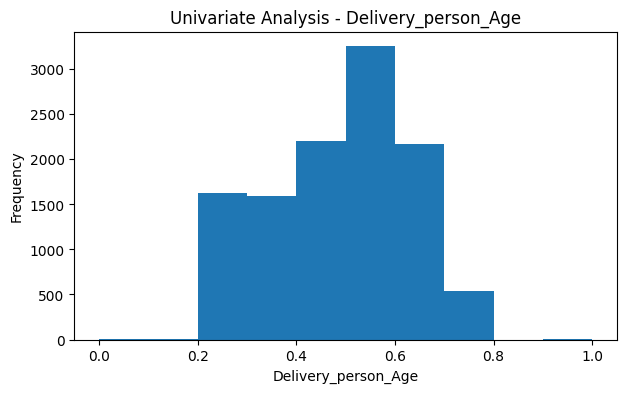

In [32]:

numeric_columns = df.select_dtypes(include=np.number).columns

if len(numeric_columns) > 0:
    column = numeric_columns[0]
    plt.figure(figsize=(7, 4))
    plt.hist(df[column].dropna())
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.title("Univariate Analysis - " + column)
    plt.show()


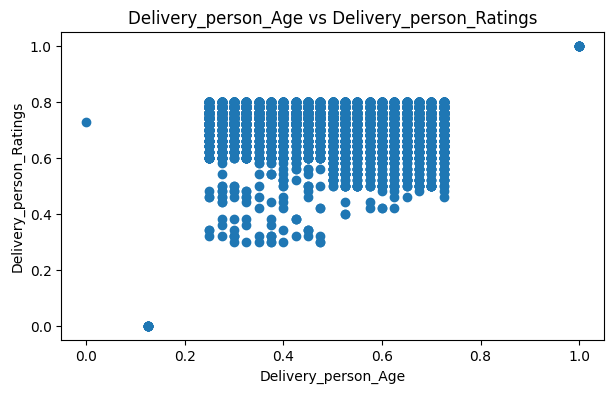

In [33]:

if "Delivery_person_Age" in df.columns and "Delivery_person_Ratings" in df.columns:
    x = "Delivery_person_Age"
    y = "Delivery_person_Ratings"

    plt.figure(figsize=(7, 4))
    plt.scatter(df[x], df[y])
    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(x + " vs " + y)
    plt.show()
else:
    print("Required columns for bivariate analysis were not found.")


# 1.5 DATAOPS
## Automated Data Pipeline




In [34]:

logging.basicConfig(
    filename="dataops.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)

def dataops_pipeline():
    start_time = datetime.now()
    logging.info("===== DATAOPS PIPELINE STARTED =====")

    try:

        data = pd.read_csv(
            "test.csv",
            na_values=["NaN", "nan", "", "?", "NA", "null"]
        )
        logging.info("Dataset loaded successfully. Shape=%s", data.shape)


        missing_before = int(data.isna().sum().sum())
        logging.info("Missing values before preprocessing=%s", missing_before)


        numeric_cols = data.select_dtypes(include=np.number).columns
        for col in numeric_cols:
            if data[col].isna().any():
                data[col] = data[col].fillna(data[col].median())

        missing_after = int(data.isna().sum().sum())
        logging.info("Missing values after numeric imputation=%s", missing_after)


        for col in numeric_cols:
            minimum = data[col].min()
            maximum = data[col].max()
            if maximum != minimum:
                data[col] = (data[col] - minimum) / (maximum - minimum)

        logging.info("Numeric normalization completed.")


        corr = data.corr(numeric_only=True)
        logging.info("Correlation analysis completed.")


        if "Type_of_vehicle" in data.columns:
            data["Vehicle_encoded"] = (
                data["Type_of_vehicle"].astype("category").cat.codes
            )
            logging.info("Vehicle encoding completed.")


        if "Delivery_person_Age" in data.columns:
            bins = [0, 25, 35, 50, np.inf]
            labels = ["Young", "Adult", "Senior", "Older"]
            data["Age_Group"] = pd.cut(
                data["Delivery_person_Age"],
                bins=bins,
                labels=labels,
                include_lowest=True
            )
            logging.info("Age binning completed.")

        data.to_csv("processed_test.csv", index=False)
        logging.info("Processed dataset saved as processed_test.csv")


        print("\n" + "="*55)
        print("             DATAOPS CLOUD DASHBOARD")
        print("="*55)
        print("Pipeline run time :", start_time.strftime("%Y-%m-%d %H:%M:%S"))
        print("Rows              :", data.shape[0])
        print("Columns           :", data.shape[1])
        print("Missing before    :", missing_before)
        print("Missing after     :", missing_after)
        print("Preprocessing     : COMPLETED")
        print("EDA               : COMPLETED")
        print("Logging           : COMPLETED")
        print("Status            : SUCCESS")
        print("="*55)

        logging.info("===== DATAOPS PIPELINE COMPLETED SUCCESSFULLY =====")

    except Exception as e:
        logging.exception("Pipeline failed: %s", e)
        print("Pipeline failed:", e)


## Schedule the DataOps pipeline every 2 minutes

The following scheduler runs the complete pipeline once, waits 2 minutes, and runs it again.

**Important:** In Google Colab, a continuously running cell may stop when the Colab runtime disconnects. For the assignment demonstration, you can run a few cycles and show the logs/dashboard.


In [39]:
# Run the pipeline every 2 minutes.
# Change MAX_RUNS if you want a shorter classroom demonstration.

MAX_RUNS = 3

for run_number in range(1, MAX_RUNS + 1):
    print(f"\n\n******** DATAOPS RUN {run_number}/{MAX_RUNS} ********")
    dataops_pipeline()

    if run_number < MAX_RUNS:
        print("\nNext pipeline run will start in 2 minutes...")
        time.sleep(120)

print("\nScheduled DataOps demonstration completed.")

# Ensure all loggers are flushed and handlers are closed to make the log file reliably accessible.
import logging
logging.shutdown()



******** DATAOPS RUN 1/3 ********

             DATAOPS CLOUD DASHBOARD
Pipeline run time : 2026-09-17 13:52:49
Rows              : 11399
Columns           : 21
Missing before    : 2221
Missing after     : 987
Preprocessing     : COMPLETED
EDA               : COMPLETED
Logging           : COMPLETED
Status            : SUCCESS

Next pipeline run will start in 2 minutes...


******** DATAOPS RUN 2/3 ********

             DATAOPS CLOUD DASHBOARD
Pipeline run time : 2026-09-17 13:54:49
Rows              : 11399
Columns           : 21
Missing before    : 2221
Missing after     : 987
Preprocessing     : COMPLETED
EDA               : COMPLETED
Logging           : COMPLETED
Status            : SUCCESS

Next pipeline run will start in 2 minutes...


******** DATAOPS RUN 3/3 ********

             DATAOPS CLOUD DASHBOARD
Pipeline run time : 2026-09-17 13:56:49
Rows              : 11399
Columns           : 21
Missing before    : 2221
Missing after     : 987
Preprocessing     : COMPLETED
EDA   

# DataOps Activity Log

Display the log generated by the automated pipeline.


In [36]:
try:
    with open("dataops.log", "r") as file:
        print(file.read())
except FileNotFoundError:
    print("No log file found. Run the DataOps pipeline first.")


No log file found. Run the DataOps pipeline first.
